<a href="https://colab.research.google.com/github/GehadHelmy/github_SNA/blob/main/Project_SNA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Libraries**

In [83]:
import pandas as pd
import numpy as np
import json
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import networkx.algorithms.community as nx_comm
from matplotlib.collections import LineCollection
from sklearn.metrics import normalized_mutual_info_score
from scipy.sparse import csr_matrix
import graphistry


## **Dataset Understanding**

In [4]:
edges_df = pd.read_csv("musae_git_edges.csv")
target_df = pd.read_csv("musae_git_target.csv")
with open("musae_git_features.json", "r") as file:
    features_data = json.load(file)

In [5]:
print("Edges Shape:", edges_df.shape)
print("Target Shape:", target_df.shape)
print("Number of Feature Records:", len(features_data))

Edges Shape: (289003, 2)
Target Shape: (37700, 3)
Number of Feature Records: 37700


In [6]:
print("Edges:")
display(edges_df.head())
print("Target:")
display(target_df.head())

Edges:


,id_1,id_2
0,0,23977
1,1,34526
2,1,2370
3,1,14683
4,1,29982


Target:


,id,name,ml_target
0,0,Eiryyy,0
1,1,shawflying,0
2,2,JpMCarrilho,1
3,3,SuhwanCha,0
4,4,sunilangadi2,1


In [ ]:
print(edges_df.columns)
print(target_df.columns)

Index(['id_1', 'id_2'], dtype='object')
Index(['id', 'name', 'ml_target'], dtype='object')


In [ ]:
for i, (node_id, features) in enumerate(features_data.items()):
    print(node_id, features)
    if i == 4:
        break

0 [1574, 3773, 3571, 2672, 2478, 2534, 3129, 3077, 1171, 2045, 1539, 902, 1532, 2472, 1122, 2480, 3098, 2115, 1578]
1 [1193, 376, 73, 290, 3129, 1852, 3077, 1171, 1022, 2045, 536, 2040, 1533, 1532, 2472, 673, 798]
2 [1574, 3773, 925, 1728, 2815, 2963, 3077, 364, 1171, 536, 1867, 2472, 1122, 2532, 664, 28, 3311, 1768, 869]
3 [3964, 3773, 4003, 928, 1852, 3077, 364, 1022, 3763, 2045, 3859, 3771, 234, 664, 703]
4 [1929, 3773, 1793, 3511, 1290, 3129, 3077, 364, 1171, 1022, 2045, 536, 1119, 91, 1532, 3771, 1122, 703, 1001]


## **Data Preprocessing & Cleaning**

In [ ]:
print("Edges Missing Values:")
print(edges_df.isnull().sum())
print("\nTarget Missing Values:")
print(target_df.isnull().sum())

Edges Missing Values:
id_1    0
id_2    0
dtype: int64

Target Missing Values:
id           0
name         0
ml_target    0
dtype: int64


In [7]:
edges_df["source"] = edges_df["id_1"].astype(int)

edges_df["target"] = edges_df["id_2"].astype(int)

edges_df["source_id"] = edges_df[["source", "target"]].min(axis=1)

edges_df["target_id"] = edges_df[["source", "target"]].max(axis=1)

print("Original Edges:", len(edges_df))
edges_df = edges_df.drop_duplicates(
    subset=["source_id", "target_id"])
edges_df = edges_df[["source_id", "target_id"]]
print("After Removing Duplicates:", len(edges_df))

Original Edges: 289003
After Removing Duplicates: 289003


In [8]:
self_loops = edges_df[
    edges_df["source_id"] == edges_df["target_id"]]
print("Number of Self Loops:", len(self_loops))

Number of Self Loops: 0


In [ ]:
print("Duplicate Developer IDs:",target_df["id"].duplicated().sum())

Duplicate Developer IDs: 0


## **Graph Construction**

In [9]:
feature_nodes = set(map(int, features_data.keys()))
len(feature_nodes)

37700

In [10]:
G = nx.Graph()
G.add_nodes_from(feature_nodes)
G.add_edges_from(
    edges_df[["source_id", "target_id"]].itertuples(
        index=False,
        name=None
    ))
print("Number of Nodes:", G.number_of_nodes())
print("Number of Edges:", G.number_of_edges())

Number of Nodes: 37700
Number of Edges: 289003


### **Edge List**

In [11]:
edge_list = list(G.edges())
print(edge_list[:10])

[(0, 23977), (1, 34526), (1, 2370), (1, 14683), (1, 29982), (1, 21142), (1, 20363), (1, 23830), (1, 34035), (2, 3812)]


In [12]:
edge_list_df = pd.DataFrame(
    edge_list,
    columns=["Source", "Target"])
edge_list_df.to_csv("edge_list.csv", index=False)
edge_list_df.head()

,Source,Target
0,0,23977
1,1,34526
2,1,2370
3,1,14683
4,1,29982


### **Adjacency List**

In [13]:
adjacency_list = nx.to_dict_of_lists(G)
for node, neighbors in list(adjacency_list.items())[:5]:
    print(node, ":", neighbors)

0 : [23977]
1 : [34526, 2370, 14683, 29982, 21142, 20363, 23830, 34035]
2 : [3812]
3 : [4950, 18029, 3358, 34935, 5916]
4 : [2865, 9342]


In [14]:
with open("adjacency_list.json", "w") as file:
    json.dump(adjacency_list, file)

### **Adjacency Matrix**

In [15]:
A = nx.to_scipy_sparse_array(
    G,
    format="csr",
    dtype=np.int8)
print("Matrix Shape:", A.shape)
print("Number of Connections:", A.nnz)
print("Matrix Type:", type(A))

Matrix Shape: (37700, 37700)
Number of Connections: 578006
Matrix Type: <class 'scipy.sparse._csr.csr_array'>


In [ ]:
graphistry.register(api=3, username="", password="")
g = graphistry.edges(
    edges_df,
    source="source_id",
    destination="target_id"
)

g2 = g.scene_settings(
    show_arrows=False,
    point_size=2.0,
    edge_curvature=0.0,
    point_opacity=1.0,
    edge_opacity=0.47
)

g2.plot()

In [ ]:
graph_url = g2.plot(render=False)
print(graph_url)

https://hub.graphistry.com/graph/graph.html?dataset=6525aa83ea2c4c86a44b95ff0ee29378&type=arrow&viztoken=71c1bb95-12b9-42f4-8f0a-76f913d08709&usertag=d5a0cd15-pygraphistry-0.62.1&splashAfter=1795185985&info=true&showArrows=False&pointSize=2.0&edgeCurvature=0.0&edgeOpacity=0.47&pointOpacity=1.0


# **Centrality Measures**

In [30]:
degree = dict(G.degree())
degree

{0: 1,
 1: 8,
 2: 1,
 3: 5,
 4: 2,
 5: 1,
 6: 6,
 7: 8,
 8: 8,
 9: 7,
 10: 66,
 11: 2,
 12: 6,
 13: 3,
 14: 18,
 15: 18,
 16: 1,
 17: 3,
 18: 3,
 19: 22,
 20: 4,
 21: 33,
 22: 7,
 23: 12,
 24: 18,
 25: 14,
 26: 7,
 27: 70,
 28: 1,
 29: 2,
 30: 6,
 31: 7,
 32: 2,
 33: 2,
 34: 4,
 35: 27,
 36: 23,
 37: 1,
 38: 127,
 39: 1,
 40: 5,
 41: 7,
 42: 55,
 43: 8,
 44: 2,
 45: 3,
 46: 3,
 47: 1,
 48: 2,
 49: 5,
 50: 2,
 51: 5,
 52: 31,
 53: 2,
 54: 1,
 55: 3,
 56: 88,
 57: 1,
 58: 7,
 59: 1,
 60: 1,
 61: 21,
 62: 1,
 63: 1,
 64: 1,
 65: 3,
 66: 4,
 67: 27,
 68: 4,
 69: 12,
 70: 1,
 71: 3,
 72: 6,
 73: 1267,
 74: 6,
 75: 18,
 76: 4,
 77: 1,
 78: 15,
 79: 1,
 80: 1,
 81: 19,
 82: 2,
 83: 7,
 84: 2,
 85: 5,
 86: 54,
 87: 24,
 88: 44,
 89: 5,
 90: 5,
 91: 2,
 92: 55,
 93: 1,
 94: 144,
 95: 1,
 96: 1,
 97: 9,
 98: 23,
 99: 19,
 100: 1,
 101: 47,
 102: 2,
 103: 3,
 104: 8,
 105: 13,
 106: 5,
 107: 47,
 108: 23,
 109: 4,
 110: 6,
 111: 2,
 112: 1,
 113: 7,
 114: 7,
 115: 5,
 116: 9,
 117: 2,
 118: 6,
 1

In [32]:
sorted_degree = sorted(degree.items(),key=lambda x: x[1],)

print(sorted_degree)

[(0, 1), (2, 1), (5, 1), (16, 1), (28, 1), (37, 1), (39, 1), (47, 1), (54, 1), (57, 1), (59, 1), (60, 1), (62, 1), (63, 1), (64, 1), (70, 1), (77, 1), (79, 1), (80, 1), (93, 1), (95, 1), (96, 1), (100, 1), (112, 1), (123, 1), (128, 1), (153, 1), (160, 1), (169, 1), (170, 1), (172, 1), (188, 1), (196, 1), (204, 1), (209, 1), (211, 1), (217, 1), (220, 1), (221, 1), (225, 1), (229, 1), (234, 1), (238, 1), (245, 1), (247, 1), (249, 1), (252, 1), (267, 1), (283, 1), (289, 1), (290, 1), (292, 1), (299, 1), (306, 1), (329, 1), (331, 1), (367, 1), (372, 1), (375, 1), (380, 1), (381, 1), (382, 1), (390, 1), (391, 1), (392, 1), (402, 1), (406, 1), (424, 1), (428, 1), (449, 1), (461, 1), (462, 1), (472, 1), (474, 1), (483, 1), (484, 1), (485, 1), (487, 1), (488, 1), (489, 1), (510, 1), (511, 1), (518, 1), (520, 1), (525, 1), (558, 1), (565, 1), (566, 1), (569, 1), (572, 1), (580, 1), (585, 1), (590, 1), (594, 1), (599, 1), (604, 1), (613, 1), (628, 1), (629, 1), (638, 1), (640, 1), (653, 1), (657

In [38]:
pagerank = nx.pagerank(G)
pagerank

{0: 5.345941140694154e-06,
 1: 1.663411550151446e-05,
 2: 5.277679195371786e-06,
 3: 1.652277241355e-05,
 4: 1.0677839223608846e-05,
 5: 5.388302079466201e-06,
 6: 1.208889395299851e-05,
 7: 1.4269485011817751e-05,
 8: 1.453048617236448e-05,
 9: 1.9019085838588833e-05,
 10: 9.697668900588504e-05,
 11: 6.964876581790242e-06,
 12: 1.3030895118784496e-05,
 13: 8.297682894302218e-06,
 14: 2.4732234377052915e-05,
 15: 3.1169919054845966e-05,
 16: 5.357384358007493e-06,
 17: 7.588174413443636e-06,
 18: 8.44839981059442e-06,
 19: 3.576701621105256e-05,
 20: 8.58923408915352e-06,
 21: 4.796089596416848e-05,
 22: 1.3416933436590143e-05,
 23: 2.3201502755459392e-05,
 24: 2.8390936320008954e-05,
 25: 2.1457858851883934e-05,
 26: 1.3334388222553946e-05,
 27: 0.00010402191880826733,
 28: 7.981994992013827e-06,
 29: 7.019037704065954e-06,
 30: 1.190335834216603e-05,
 31: 1.4242826280525718e-05,
 32: 7.52881646435952e-06,
 33: 7.627824455492647e-06,
 34: 1.1954696867257965e-05,
 35: 3.876165365802995

In [36]:
eigenvector_centrality = nx.eigenvector_centrality_numpy(G)

In [35]:
sorted_eigenvector = sorted(eigenvector_centrality.items(), key=lambda item: item[1])
sorted_eigenvector[:10]

[(13424, 3.544915370726839e-12),
 (20494, 6.520541545345933e-12),
 (32248, 1.2547342358637396e-11),
 (24549, 6.539331793265481e-11),
 (7285, 1.1173823219197055e-10),
 (21227, 1.1828265964015336e-10),
 (11247, 5.274581074126585e-10),
 (28182, 8.617291723351315e-10),
 (21682, 9.70210006746403e-10),
 (35270, 1.0348412192154864e-09)]

In [40]:
centrality_df = pd.DataFrame({
    'Node': list(G.nodes()),
    'Degree': [degree[n] for n in G.nodes()],
    'PageRank': [pagerank[n] for n in G.nodes()],
    'Eigenvector': [eigenvector_centrality[n] for n in G.nodes()]
})
centrality_df

,Node,Degree,PageRank,Eigenvector
0,0,1,0.000005,0.000047
1,1,8,0.000017,0.000952
2,2,1,0.000005,0.000036
3,3,5,0.000017,0.000105
4,4,2,0.000011,0.000009
...,...,...,...,...
37695,37695,1,0.000010,0.000016
37696,37696,2,0.000007,0.000204
37697,37697,4,0.000010,0.000413
37698,37698,3,0.000011,0.000039


In [41]:
degree_threshold = centrality_df['Degree'].quantile(0.75)
pagerank_threshold = centrality_df['PageRank'].quantile(0.75)
eigenvector_threshold = centrality_df['Eigenvector'].quantile(0.75)

In [42]:
filtered_nodes = centrality_df[
    (centrality_df['Degree'] >= degree_threshold) &
    (centrality_df['PageRank'] >= pagerank_threshold) &
    (centrality_df['Eigenvector'] >= eigenvector_threshold)
]['Node'].tolist()

In [43]:
G_filtered = G.subgraph(filtered_nodes).copy()

In [44]:
betweenness = nx.betweenness_centrality(G_filtered)

In [46]:
betweenness

{10: 7.387625596951878e-05,
 32781: 1.2591290026116616e-05,
 32782: 3.877043317171656e-06,
 15: 2.772817547646373e-06,
 32785: 9.828317638719406e-06,
 21: 3.1415926988692204e-05,
 24: 2.942117745016236e-06,
 32793: 1.017333414874899e-06,
 32794: 6.8351588364572e-06,
 32796: 9.81511033594657e-06,
 32799: 6.239994917058967e-06,
 35: 1.1006129634720206e-05,
 36: 8.33790395946536e-06,
 38: 0.0002082492010759969,
 32806: 1.7052882905019347e-05,
 32809: 1.2777473084773392e-05,
 42: 5.029667744871235e-05,
 32819: 1.7797732369864737e-05,
 52: 1.1482235058215111e-05,
 32821: 0.00010687795833366233,
 56: 1.7525999502941017e-05,
 61: 7.069631660448414e-06,
 67: 1.2336375013676991e-05,
 32836: 2.0505667907494256e-05,
 32839: 6.480243935678946e-06,
 73: 0.005925442063115247,
 32845: 3.731282803453555e-05,
 32848: 2.418579752888227e-06,
 81: 5.38322405826647e-06,
 86: 2.652778653223557e-05,
 87: 9.79710287186363e-06,
 88: 1.9710067009992034e-05,
 32856: 2.4929747093073545e-06,
 92: 2.504549452332078

In [45]:
closeness = nx.closeness_centrality(G_filtered)
closeness

{10: 0.4971992110453649,
 32781: 0.4345307867337792,
 32782: 0.44184252962209913,
 15: 0.4867160951498301,
 32785: 0.479020979020979,
 21: 0.4897800575114634,
 24: 0.4005338756832338,
 32793: 0.4108749511018386,
 32794: 0.4948178391959799,
 32796: 0.47938536436938994,
 32799: 0.4561047984367084,
 35: 0.44311629869216707,
 36: 0.39426926926926925,
 38: 0.4976703782673932,
 32806: 0.4874690594059406,
 32809: 0.4454969602714548,
 42: 0.4590952138121949,
 32819: 0.435883248028773,
 52: 0.4244628544487102,
 32821: 0.4597986283379542,
 56: 0.4239773950484392,
 61: 0.45098039215686275,
 67: 0.45383839838686446,
 32836: 0.42679127725856697,
 32839: 0.4265024363833243,
 73: 0.5155431937172775,
 32845: 0.4992869592774521,
 32848: 0.4834305001534213,
 81: 0.4263870094722598,
 86: 0.4304350795710675,
 87: 0.44892434819774896,
 88: 0.42609871534820826,
 32856: 0.4258108108108108,
 92: 0.44091513328202614,
 32861: 0.4375781141508124,
 94: 0.4973954222573007,
 32863: 0.478076164466697,
 98: 0.4432409

In [47]:
results_df = pd.DataFrame({
    'Node': list(G_filtered.nodes()),
    'Degree': [degree[n] for n in G_filtered.nodes()],
    'PageRank': [pagerank[n] for n in G_filtered.nodes()],
    'Eigenvector': [eigenvector_centrality[n] for n in G_filtered.nodes()],
    'Betweenness': [betweenness[n] for n in G_filtered.nodes()],
    'Closeness': [closeness[n] for n in G_filtered.nodes()]
})

In [48]:
results_df

,Node,Degree,PageRank,Eigenvector,Betweenness,Closeness
0,10,66,0.000097,0.012230,0.000074,0.497199
1,32781,20,0.000033,0.003841,0.000013,0.434531
2,32782,26,0.000042,0.005773,0.000004,0.441843
3,15,18,0.000031,0.007655,0.000003,0.486716
4,32785,15,0.000028,0.005029,0.000010,0.479021
...,...,...,...,...,...,...
6298,32750,27,0.000043,0.003426,0.000006,0.421510
6299,32753,345,0.000494,0.025402,0.000923,0.505454
6300,32755,23,0.000032,0.006301,0.000013,0.481657
6301,32759,16,0.000028,0.006698,0.000005,0.466331


In [101]:
degrees = [d for _, d in G_filtered.degree()]
deg_counts = Counter(degrees)
deg_df = (pd.DataFrame(sorted(deg_counts.items()), columns=["Degree", "Count"])
            .assign(P_k=lambda d: d["Count"] / G_filtered.number_of_nodes()))
print(deg_df.head(10))
print(f"Mean: {np.mean(degrees):.2f} | Median: {np.median(degrees)} | Max: {max(degrees)}")


   Degree  Count       P_k
0       4      1  0.000159
1       5      6  0.000952
2       6     16  0.002538
3       7     27  0.004284
4       8     51  0.008091
5       9     92  0.014596
6      10    125  0.019832
7      11    187  0.029668
8      12    209  0.033159
9      13    249  0.039505
Mean: 40.42 | Median: 23.0 | Max: 3781


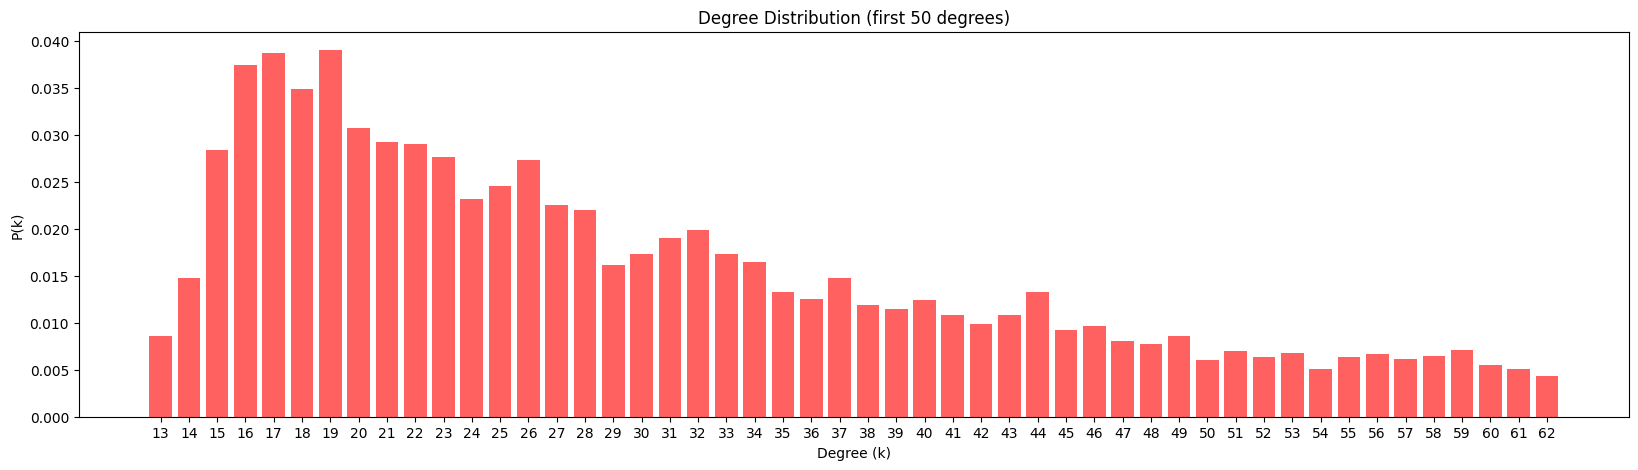

In [99]:
top = deg_df.head(50)

plt.figure(figsize=(20, 5))
plt.bar(top["Degree"], top["P_k"], color="#ff6161")
plt.xticks(top["Degree"])
plt.xlabel("Degree (k)")
plt.ylabel("P(k)")
plt.title("Degree Distribution (first 50 degrees)")
plt.show()

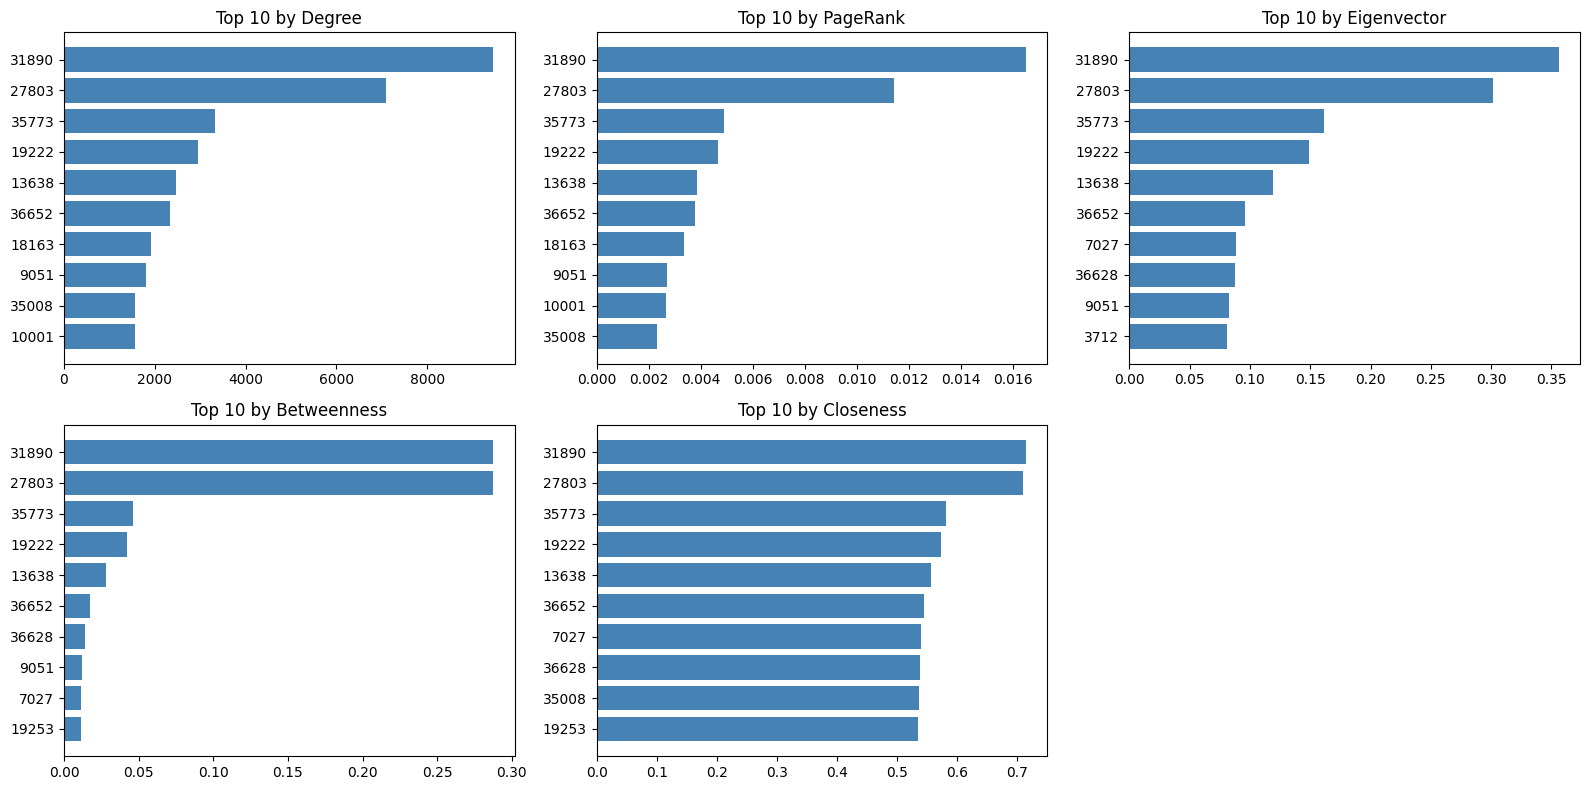

In [80]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cols):
    t = results_df.nlargest(10, col)
    ax.barh(t["Node"].astype(str), t[col], color="steelblue")
    ax.invert_yaxis(); ax.set_title(f"Top 10 by {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

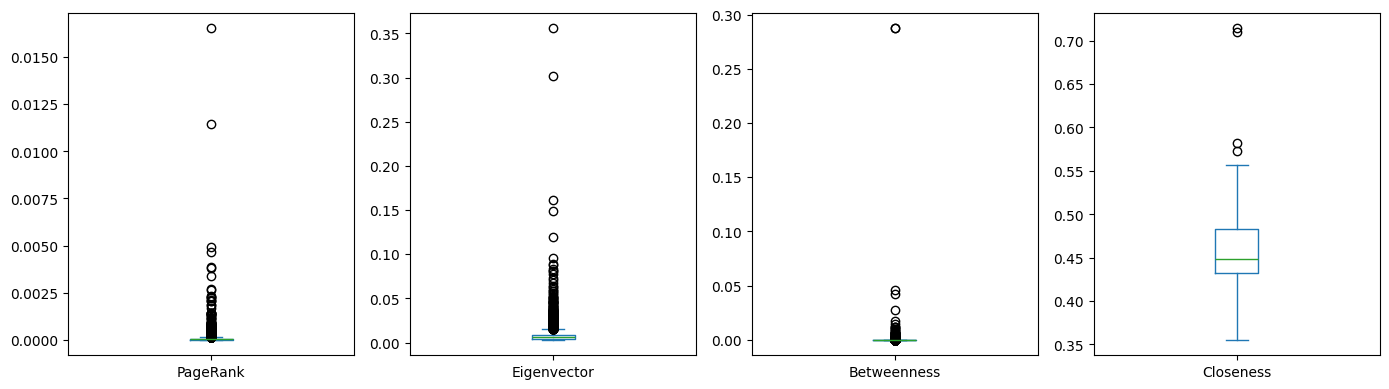

In [100]:
results_df[cols[1:]].plot(kind="box", subplots=True, layout=(1, 4), figsize=(14, 4))
plt.tight_layout(); plt.show()

# **Community Detection & Modularity**

In [84]:
communities = nx_comm.louvain_communities(G, seed=42)
print("Number of communities:", len(communities))
print("Top 5 sizes:", sorted(map(len, communities), reverse=True)[:5])

node_comm = {n: i for i, c in enumerate(communities) for n in c}
centrality_df["Community"] = centrality_df["Node"].map(node_comm)

Number of communities: 33
Top 5 sizes: [7693, 7440, 7436, 5053, 3131]


In [104]:
lab = target_df.set_index("id")["ml_target"]
nodes = [n for n in G.nodes() if n in lab.index]
nmi = normalized_mutual_info_score([lab[n] for n in nodes], [node_comm[n] for n in nodes])
print(f"NMI vs ml_target: {nmi:.3f}")

NMI vs ml_target: 0.111


In [103]:
rows = []
for i, c in enumerate(communities):
    top = max(c, key=lambda n: degree[n])
    rows.append({"Community": i, "Size": len(c),
                 "AvgDegree": np.mean([degree[n] for n in c]),
                 "TopNode": top, "TopNodeDegree": degree[top]})
comm_df = pd.DataFrame(rows).sort_values("Size", ascending=False)
comm_df.head(10)

,Community,Size,AvgDegree,TopNode,TopNodeDegree
12,12,7693,17.894449,31890,9458
21,21,7440,12.178226,27803,7085
26,26,7436,18.940559,13638,2468
14,14,5053,14.719770,35773,3324
18,18,3131,16.835196,36652,2343
32,32,2467,11.227807,30235,423
3,3,2282,12.505697,5629,1316
4,4,533,9.602251,22782,296
7,7,531,11.459510,35822,202
5,5,488,15.397541,15750,313


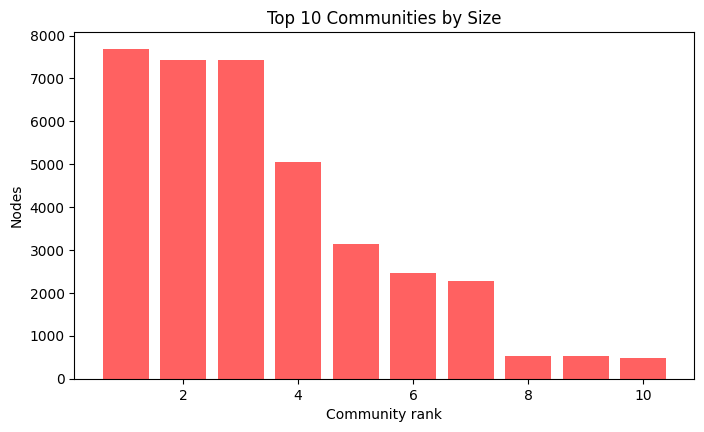

In [91]:
sizes = sorted(map(len, communities), reverse=True)
plt.figure(figsize=(8, 4.5))
plt.bar(range(1, 11), sizes[:10], color="#ff6161")
plt.xlabel("Community rank"); plt.ylabel("Nodes"); plt.title("Top 10 Communities by Size")
plt.show()

In [89]:
Q = nx_comm.modularity(G, communities)
print(f"Modularity: {Q:.4f}")

Modularity: 0.4543


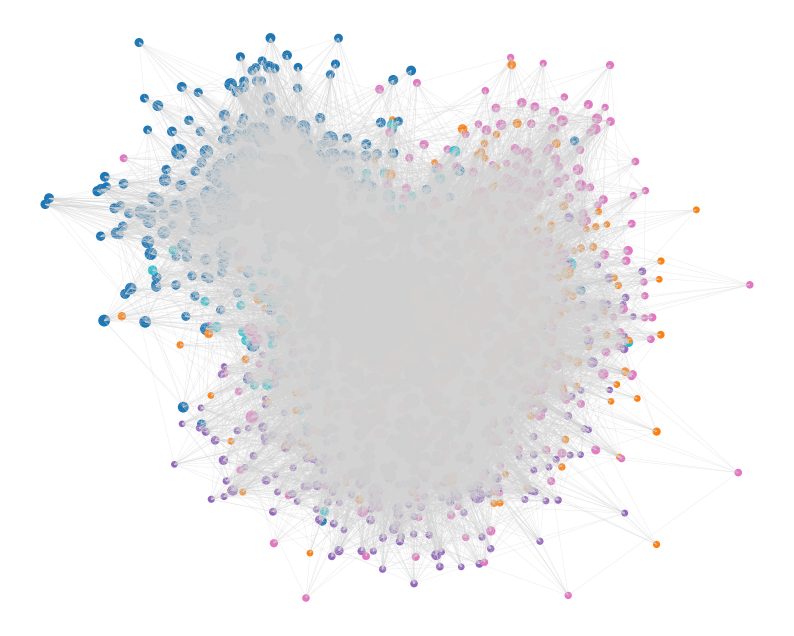

In [96]:

TOP_COMMS, PER_COMM = 5, 300

top_comms = sorted(communities, key=len, reverse=True)[:TOP_COMMS]
keep = [n for c in top_comms
        for n in sorted(c, key=lambda x: degree[x], reverse=True)[:PER_COMM]]
H = G.subgraph(keep)

pos = nx.spring_layout(H, seed=42, iterations=30, k=1 / np.sqrt(len(H)))

edges = np.array([[pos[u], pos[v]] for u, v in H.edges()])
fig, ax = plt.subplots(figsize=(10, 8))
ax.add_collection(LineCollection(edges, colors="lightgray", linewidths=0.3, alpha=0.5))
xy = np.array([pos[n] for n in H.nodes()])
ax.scatter(xy[:, 0], xy[:, 1], s=[degree[n] * 0.5 + 5 for n in H.nodes()],
           c=[node_comm[n] for n in H.nodes()], cmap="tab10", linewidths=0)
ax.autoscale(); ax.axis("off")
plt.show()

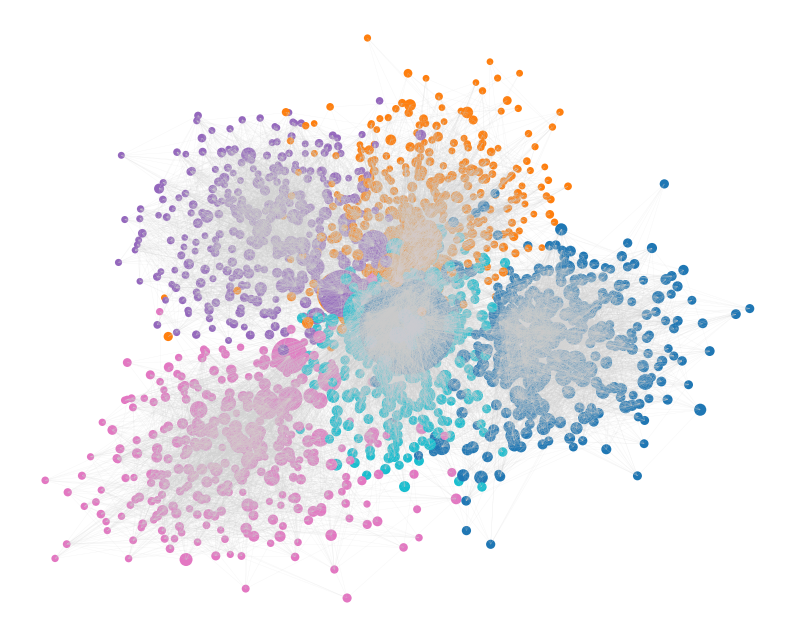

In [102]:
# Edges inside the same community only
intra = [(u, v) for u, v in H.edges() if node_comm[u] == node_comm[v]]
rng = np.random.default_rng(0)
comm_ids = sorted({node_comm[n] for n in H.nodes()})
centers = {c: np.array([np.cos(2*np.pi*i/len(comm_ids)),
                        np.sin(2*np.pi*i/len(comm_ids))])
           for i, c in enumerate(comm_ids)}
init = {n: centers[node_comm[n]] + rng.normal(0, 0.1, 2) for n in H.nodes()}

pos = nx.spring_layout(H, pos=init, iterations=20, k=0.15, seed=42)

edges = np.array([[pos[u], pos[v]] for u, v in intra])
fig, ax = plt.subplots(figsize=(10, 8))
ax.add_collection(LineCollection(edges, colors="lightgray", linewidths=0.2, alpha=0.3))
xy = np.array([pos[n] for n in H.nodes()])
ax.scatter(xy[:, 0], xy[:, 1], s=[degree[n] * 0.5 + 5 for n in H.nodes()],
           c=[node_comm[n] for n in H.nodes()], cmap="tab10", linewidths=0)
ax.autoscale(); ax.axis("off"); plt.show()